# Notebook 26 — Why does additive ESCM fail to replace obsolete activity?

## Question and experimental contract

In Notebook 25, **ESCM 2.0 + fading** (the approved video model) replaced the old vertical edge successfully, while the additive model with **1 ms refractory**, recurrent weight **3**, and inhibitory multiplier **1** preserved both old and new edges. This notebook diagnoses **why** without adjusting parameters or adding a mechanism.

We reuse Notebook 25's **9 × 9**, spatially homogeneous surround graph, camera schedules, differential equations, and the two reference configurations. The target is **ESCM 2.0 + fading**, not the earlier, non-fading Notebook 20 model.

| Property | Approved reference | Additive candidate |
|---|---|---|
| Self-excitation on spike | `Iexc_post = 8*support_post` | `Iexc_post += 3*support_post` |
| Absolute refractory | none | **1 ms** |
| Inhibitory kernel | same | same, multiplier **1** |
| Sensory support | camera-triggered, decay **120 ms** | same |
| Simulation step | **0.05 ms** | **0.05 ms** |

The question is **not** whether additive synapses are generally inferior. We ask, for this precisely specified example: does failure come from (a) too little inhibitory drive reaching the old edge, (b) excessive recurrent excitation in the old edge despite inhibition, or (c) some combination? Measurements can distinguish these contributions, but do not prove a general causal mechanism without intervention experiments.

**No video rendering is involved.** All firing and state measurements come directly from Brian2 spike and state monitors. This is a diagnostic notebook; the approved model is not modified.

## 1. Exact network and stimulus

Every pixel contains a current-based LIF neuron:

\[
\tau_m\dot v_i=-v_i+I_{\mathrm{ext},i}+I_{\mathrm{exc},i}-I_{\mathrm{inh},i},
\qquad \tau_x\dot I_{x,i}=-I_{x,i}.
\]

Here \(\tau_m=10\) ms; \((\tau_{\rm ext},\tau_{\rm exc},\tau_{\rm inh})=(3,5,12)\) ms. An external event adds 22 to \(I_{\rm ext}\) and sets `support=1`. The support trace decays with time constant 120 ms. Threshold is \(v>1\) and each spike resets \(v=0\). Refractoriness prevents spiking but **does not freeze** any differential equation.

A spike at pixel \(j\) adds \(w_{ji}\) to \(I_{\rm inh,i}\) where

\[
w_{ji}=0.1\exp[-d_{ij}^2/(2\cdot 2.5^2)]
\quad\text{if }1.5<d_{ij}\le 5.5;
\qquad w_{ji}=0\text{ otherwise}.
\]

The old edge occupies column 2 and the new edge column 5 (rows 2–6). Each pixel of the old edge receives events at 2, 4, and 6 ms; each pixel of the new edge receives events at 20, 22, and 24 ms. Both models receive **identical events**.

We simulate three conditions per model: **old alone**, **new alone**, and **both**. The controls let us tell suppression by competition apart from spontaneous fading.

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


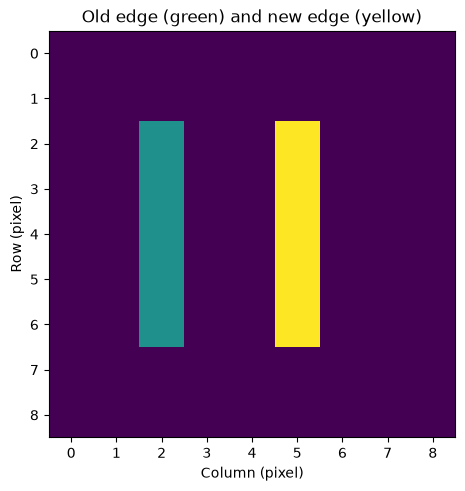

81 neurons, 3620 directed inhibitory synapses; 10 recorded neurons


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"  # Six short diagnostic runs; avoid standalone compilation overhead.

width = height = 9
n = width * height
dt_ms = 0.05
xy = np.column_stack((np.arange(n) % width, np.arange(n) // width))
old = np.array([y*width + 2 for y in range(2, 7)], dtype=int)
new = np.array([y*width + 5 for y in range(2, 7)], dtype=int)
observed = np.r_[old, new]

distance = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
targets, sources = np.where((distance > 1.5) & (distance <= 5.5))
inhibitory_weights = 0.1 * np.exp(-distance[targets, sources]**2/(2*2.5**2))

camera_schedule = {
    "old": [(old, (2., 4., 6.))],
    "new": [(new, (20., 22., 24.))],
    "both": [(old, (2., 4., 6.)), (new, (20., 22., 24.))],
}
settings = {
    "ESCM 2.0 + fading": dict(mode="refresh", weight=8., refractory_ms=0.),
    "Additive + refractory": dict(mode="additive", weight=3., refractory_ms=1.),
}

fig, ax = plt.subplots(figsize=(5.2, 4.8), constrained_layout=True)
image = np.zeros((height, width))
image[old // width, old % width] = 1
image[new // width, new % width] = 2
ax.imshow(image, cmap="viridis", vmin=0, vmax=2, interpolation="nearest", origin="upper")
ax.set(xlabel="Column (pixel)", ylabel="Row (pixel)", title="Old edge (green) and new edge (yellow)",
       xticks=range(width), yticks=range(height))
plt.show()
print(f"{n} neurons, {len(sources)} directed inhibitory synapses; {len(observed)} recorded neurons")

## 2. Record currents, membrane voltage, and every output spike

The following simulation is the same **Brian2 model as Notebook 25**, with a StateMonitor recording all ten edge neurons. We record four components separately:

\[
I_{\rm recurrent}=I_{\rm exc},\qquad
I_{\rm inhibitory}=I_{\rm inh},\qquad
I_{\rm net}=I_{\rm ext}+I_{\rm exc}-I_{\rm inh},\qquad v.
\]

The net-drive expression is the instantaneous forcing term in the membrane equation, **not** an instantaneous spike prediction: membrane history, reset, threshold and refractoriness also matter. Recording the full ten-pixel population avoids drawing conclusions from an arbitrarily selected survivor.

In [2]:
def simulate(schedule, *, mode, weight, refractory_ms, duration_ms=65.):
    b2.start_scope()
    b2.defaultclock.dt = dt_ms * b2.ms

    event_ids, event_times = [], []
    for pixels, pulses in schedule:
        for t in pulses:
            for pixel in pixels:
                event_ids.append(int(pixel))
                event_times.append(float(t))
    order = np.argsort(event_times, kind="stable")
    camera = b2.SpikeGeneratorGroup(
        n, np.asarray(event_ids, dtype=int)[order],
        np.asarray(event_times, dtype=float)[order]*b2.ms)

    parameters = dict(tau_m=10*b2.ms, tau_ext=3*b2.ms,
                      tau_exc=5*b2.ms, tau_inh=12*b2.ms,
                      tau_support=120*b2.ms, v_threshold=1., camera_gain=22.)
    equations = """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
        dsupport/dt = -support/tau_support : 1
    """
    neurons = b2.NeuronGroup(
        n, equations, threshold="v > v_threshold", reset="v = 0",
        refractory=refractory_ms*b2.ms if refractory_ms else False,
        method="exact", namespace=parameters)

    sensory = b2.Synapses(camera, neurons,
                         on_pre="Iext_post += camera_gain; support_post = 1",
                         namespace=parameters)
    sensory.connect(j="i")

    if mode == "refresh":
        rule = "Iexc_post = recurrence_gain*support_post"
    else:
        rule = "Iexc_post += recurrence_gain*support_post"
    recurrence = b2.Synapses(neurons, neurons, on_pre=rule,
                             namespace={"recurrence_gain": float(weight)})
    recurrence.connect(i=np.arange(n), j=np.arange(n))

    inhibition = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
    inhibition.connect(i=sources, j=targets)
    inhibition.w = inhibitory_weights

    spikes = b2.SpikeMonitor(neurons)
    state = b2.StateMonitor(neurons, ["v", "Iext", "Iexc", "Iinh", "support"],
                            record=observed)
    b2.Network(camera, neurons, sensory, recurrence, inhibition, spikes, state).run(
        duration_ms*b2.ms)
    result = {"t": np.asarray(spikes.t/b2.ms),
              "i": np.asarray(spikes.i, dtype=int),
              "time": np.asarray(state.t/b2.ms),
              "pixels": observed.copy()}
    for name in ("v", "Iext", "Iexc", "Iinh", "support"):
        result[name] = np.asarray(getattr(state, name))
    return result

runs = {}
for model, parameters in tqdm(settings.items(), desc="Models"):
    for condition, schedule in tqdm(camera_schedule.items(), desc=model, leave=False):
        runs[(model, condition)] = simulate(schedule, **parameters)

assert all(run["Iexc"].shape[0] == len(observed) for run in runs.values())
assert all(np.isfinite(run["Iinh"]).all() for run in runs.values())
print("Completed six runs: two models × (old only, new only, both).")

Models: 100%|██████████| 2/2 [00:03<00:00,  1.88s/it]

Completed six runs: two models × (old only, new only, both).


## 3. Confirm the replacement failure directly from spikes

For each of the two windows **[32,42) ms** and **[42,52) ms**, we count spikes for each of five old and five new pixels.

A pixel is called *persistent* if it emits at least two spikes in **both** windows. Old-edge suppression requires zero spikes in both windows for **every** old pixel. The isolated controls tell us whether each edge would have remained active without competition. These are the same strict criteria used in Notebook 25.

This check precedes any analysis of currents: otherwise, a putative explanation could concern a different network behavior than the one we set out to diagnose.

In [3]:
windows = [(32., 42.), (42., 52.)]

def counts(run, pixels, start, stop):
    valid = (run["t"] >= start) & (run["t"] < stop)
    return np.bincount(run["i"][valid], minlength=n)[pixels]

rows = []
for model in settings:
    for population, pixels in (("old", old), ("new", new)):
        isolated = runs[(model, population)]
        combined = runs[(model, "both")]
        for a, b in windows:
            ci = counts(isolated, pixels, a, b)
            cb = counts(combined, pixels, a, b)
            rows.append(dict(model=model, population=population, window=f"{a:g}–{b:g} ms",
                             isolated_spikes=int(ci.sum()), combined_spikes=int(cb.sum()),
                             isolated_active_pixels=int((ci >= 2).sum()),
                             combined_active_pixels=int((cb >= 2).sum()),
                             combined_silent_pixels=int((cb == 0).sum())))
summary = pd.DataFrame(rows)
display(summary)

for model in settings:
    old_isolated = [counts(runs[(model, "old")], old, a, b) for a, b in windows]
    new_isolated = [counts(runs[(model, "new")], new, a, b) for a, b in windows]
    old_competing = [counts(runs[(model, "both")], old, a, b) for a, b in windows]
    new_competing = [counts(runs[(model, "both")], new, a, b) for a, b in windows]
    eligible = all((c >= 2).all() for c in old_isolated + new_isolated)
    success = eligible and all((c == 0).all() for c in old_competing) and all(
        (c >= 2).all() for c in new_competing)
    print(f"{model}: isolated controls eligible={eligible}; strict replacement={success}")

,model,population,window,isolated_spikes,combined_spikes,isolated_active_pixels,combined_active_pixels,combined_silent_pixels
0,ESCM 2.0 + fading,old,32–42 ms,15,0,5,0,5
1,ESCM 2.0 + fading,old,42–52 ms,15,0,5,0,5
2,ESCM 2.0 + fading,new,32–42 ms,22,20,5,5,0
3,ESCM 2.0 + fading,new,42–52 ms,20,17,5,5,0
4,Additive + refractory,old,32–42 ms,47,29,5,5,0
5,Additive + refractory,old,42–52 ms,38,0,5,0,5
6,Additive + refractory,new,32–42 ms,50,50,5,5,0
7,Additive + refractory,new,42–52 ms,50,44,5,5,0


ESCM 2.0 + fading: isolated controls eligible=True; strict replacement=True
Additive + refractory: isolated controls eligible=True; strict replacement=False


## 4. Compare the time courses of actual synaptic currents

The new edge begins receiving events at **20 ms** and receives its final event at **24 ms**. We therefore inspect **15–55 ms**, including the recruitment and competition periods.

For each of the five *old* pixels we plot a faint trace. The thick line gives their mean, and the corresponding *new*-edge mean appears in a separate column. The plots show the **actual state variables recorded from the network**, not reconstructed video intensities or smoothed spike counts.

Interpretation:

- If the additive model has substantially **less inhibitory current at the old edge**, inhibitory recruitment is a plausible limitation.
- If it receives comparable inhibition but maintains **much more excitatory drive**, recurrent-current accumulation is a plausible limitation.
- If both differ, the failure probably involves their interaction. The membrane-potential and spike plots are needed because a large net current alone does not imply a spike during refractoriness.

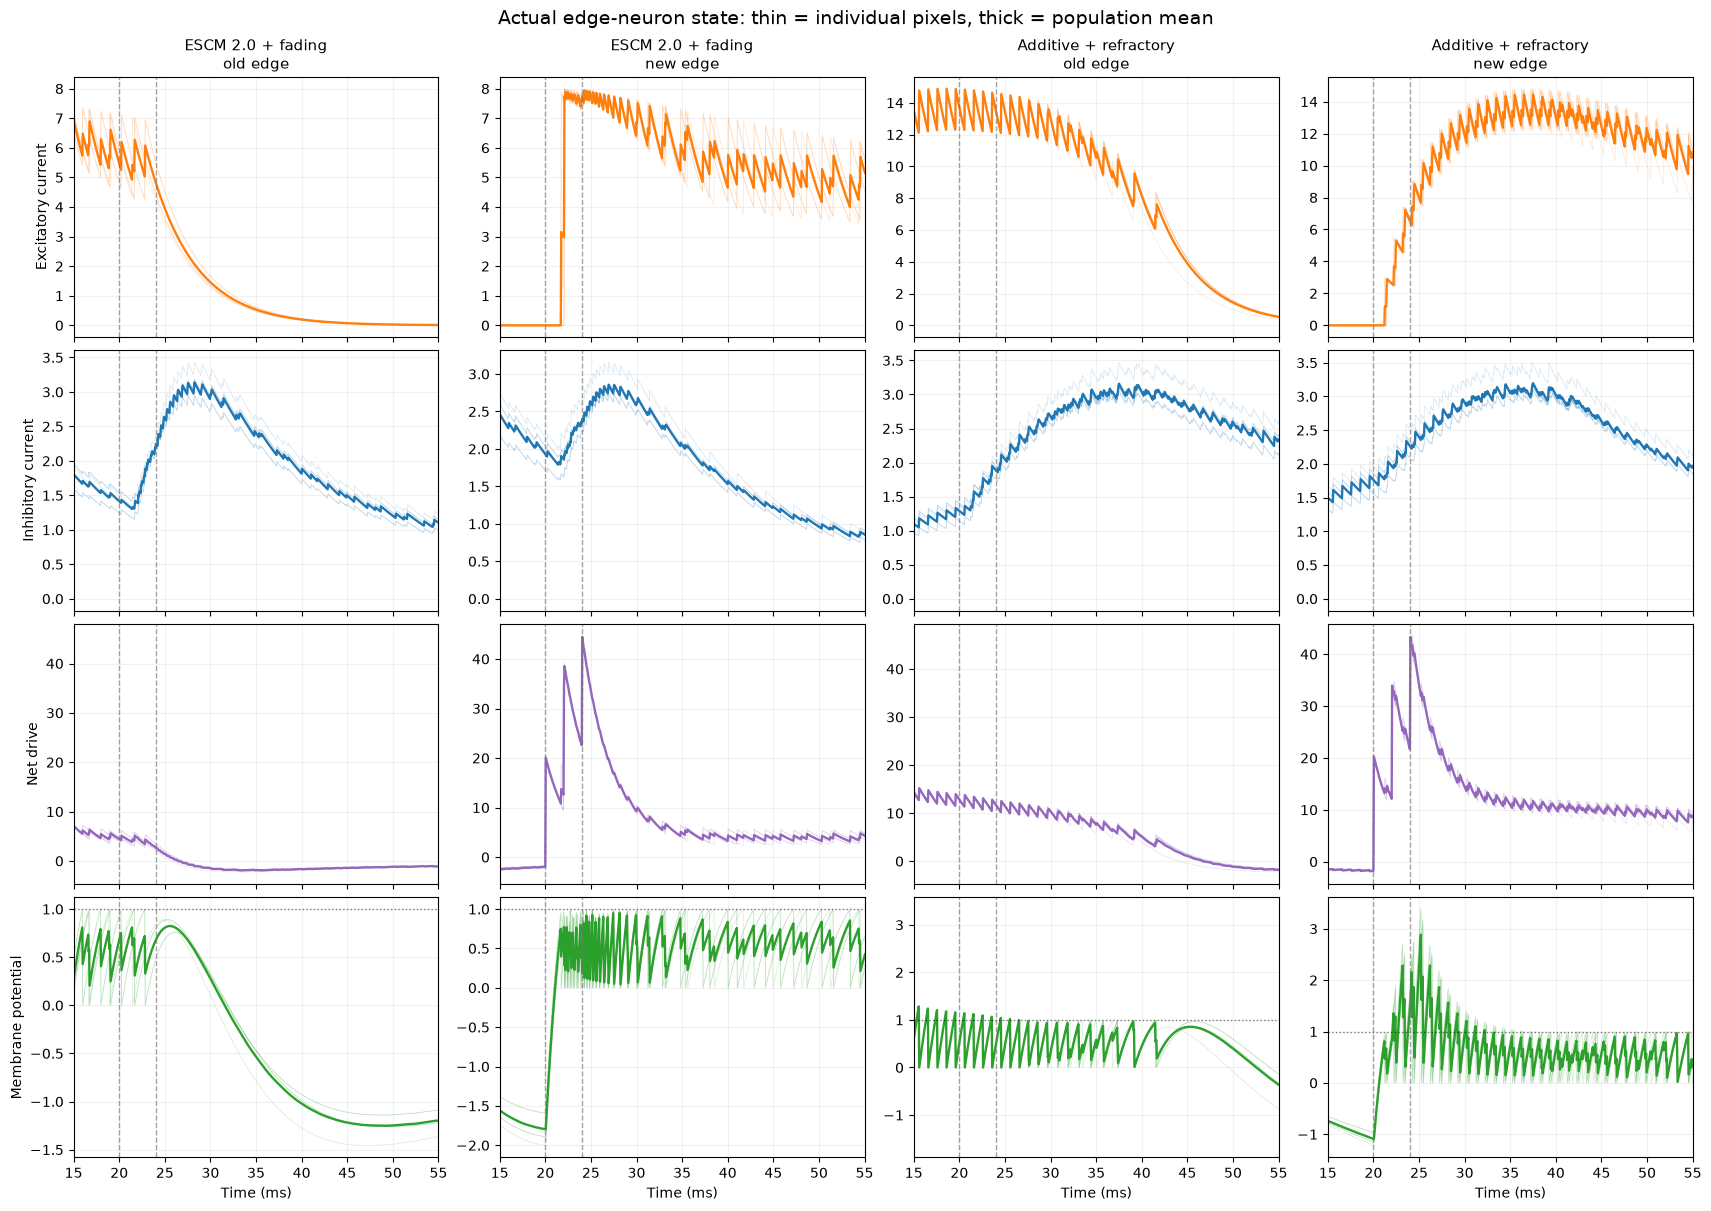

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(17, 12), sharex=True, constrained_layout=True)
colors = {"Iexc": "tab:orange", "Iinh": "tab:blue", "net": "tab:purple", "v": "tab:green"}
for col, (model, population) in enumerate(
        [(name, pop) for name in settings for pop in ("old", "new")]):
    result = runs[(model, "both")]
    sample_rows = slice(0, 5) if population == "old" else slice(5, 10)
    net = result["Iext"] + result["Iexc"] - result["Iinh"]
    traces = {"Iexc": result["Iexc"], "Iinh": result["Iinh"],
              "net": net, "v": result["v"]}
    for row, (quantity, data) in enumerate(traces.items()):
        ax = axes[row, col]
        segment = data[sample_rows]
        ax.plot(result["time"], segment.T, color=colors[quantity], lw=0.55, alpha=0.18)
        ax.plot(result["time"], segment.mean(axis=0), color=colors[quantity], lw=1.7)
        for t in (20., 24.):
            ax.axvline(t, ls="--", lw=1, color="0.45", alpha=0.65)
        ax.set_xlim(15, 55)
        ax.grid(alpha=0.17)
        if row == 0:
            ax.set_title(f"{model}\n{population} edge", fontsize=11)
        if col == 0:
            ax.set_ylabel({"Iexc": "Excitatory current", "Iinh": "Inhibitory current",
                           "net": "Net drive", "v": "Membrane potential"}[quantity])
        if row == 3:
            ax.set_xlabel("Time (ms)")
            ax.axhline(1., ls=":", lw=1, color="black", alpha=0.5)
fig.suptitle("Actual edge-neuron state: thin = individual pixels, thick = population mean", fontsize=14)
plt.show()

## 5. Quantify current balance around replacement

For each population and time window, compute the mean current across **all five pixels and all recorded samples**:

\[
\langle I_x\rangle_{P,[a,b)}
=\frac{1}{5N_t}\sum_{i\in P}\sum_{t_k\in[a,b)} I_{x,i}(t_k).
\]

Compare the combined input with its respective isolated control. A large combined-run inhibitory current is evidence of inhibitory recruitment; the **difference** against the isolated run identifies how the competing edge changes the input received by that population. This comparison does not attribute every inhibitory spike to a particular source, since firing of existing neurons may also change.

The excitatory and inhibitory currents are reported **separately**. Comparing their signs or ratios without the external current would be misleading around incoming camera events, so net drive is also reported.

In [5]:
periods = [(15., 20., "Before new input"), (20., 26., "New-edge recruitment"),
           (26., 32., "Early competition"), (32., 42., "Persistence 1"),
           (42., 52., "Persistence 2")]
records = []
for model in settings:
    for population, indices in (("old", slice(0, 5)), ("new", slice(5, 10))):
        for condition in (population, "both"):
            r = runs[(model, condition)]
            for start, stop, phase in periods:
                in_window = (r["time"] >= start) & (r["time"] < stop)
                quantities = {var: r[var][indices, :][:, in_window].mean()
                              for var in ("Iext", "Iexc", "Iinh", "v", "support")}
                records.append(dict(model=model, population=population,
                                    condition=condition, phase=phase,
                                    start_ms=start, stop_ms=stop,
                                    **quantities,
                                    net_drive=quantities["Iext"]+quantities["Iexc"]-quantities["Iinh"]))
current_table = pd.DataFrame(records)
display(current_table.loc[current_table.phase.isin(["Early competition", "Persistence 1"]),
                          ["model", "population", "condition", "phase", "Iext", "Iexc", "Iinh", "net_drive", "v"]].round(3))

old_both = current_table.query("population == 'old' and condition == 'both'")
old_only = current_table.query("population == 'old' and condition == 'old'")
old_comparison = old_both.merge(old_only, on=["model", "population", "phase", "start_ms", "stop_ms"],
                                suffixes=("_both", "_isolated"))
for term in ("Iexc", "Iinh", "net_drive"):
    old_comparison[f"delta_{term}"] = old_comparison[f"{term}_both"] - old_comparison[f"{term}_isolated"]
print("Old-edge changes introduced by competition (combined minus old-only):")
display(old_comparison[["model", "phase", "delta_Iexc", "delta_Iinh", "delta_net_drive"]].round(3))

,model,population,condition,phase,Iext,Iexc,Iinh,net_drive,v
2,ESCM 2.0 + fading,old,old,Early competition,0.022,5.137,0.996,4.163,0.577
3,ESCM 2.0 + fading,old,old,Persistence 1,0.002,4.671,0.784,3.889,0.605
7,ESCM 2.0 + fading,old,both,Early competition,0.022,1.894,2.973,-1.056,0.430
8,ESCM 2.0 + fading,old,both,Persistence 1,0.002,0.424,2.193,-1.768,-0.711
12,ESCM 2.0 + fading,new,new,Early competition,8.897,7.153,1.884,14.166,0.490
13,ESCM 2.0 + fading,new,new,Persistence 1,0.806,5.898,1.502,5.201,0.560
17,ESCM 2.0 + fading,new,both,Early competition,8.897,7.124,2.682,13.339,0.487
18,ESCM 2.0 + fading,new,both,Persistence 1,0.806,5.761,1.869,4.697,0.573
22,Additive + refractory,old,old,Early competition,0.022,12.911,1.473,11.461,0.545
23,Additive + refractory,old,old,Persistence 1,0.002,11.979,1.545,10.435,0.522


Old-edge changes introduced by competition (combined minus old-only):


,model,phase,delta_Iexc,delta_Iinh,delta_net_drive
0,ESCM 2.0 + fading,Before new input,0.000,0.000,0.000
1,ESCM 2.0 + fading,New-edge recruitment,-0.498,0.674,-1.172
2,ESCM 2.0 + fading,Early competition,-3.243,1.977,-5.220
3,ESCM 2.0 + fading,Persistence 1,-4.248,1.409,-5.657
4,ESCM 2.0 + fading,Persistence 2,-4.162,0.758,-4.920
5,Additive + refractory,Before new input,0.000,0.000,0.000
6,Additive + refractory,New-edge recruitment,0.000,0.356,-0.356
7,Additive + refractory,Early competition,-0.237,1.080,-1.317
8,Additive + refractory,Persistence 1,-2.446,1.447,-3.893
9,Additive + refractory,Persistence 2,-6.443,1.257,-7.699


## 6. Compare spike timing with the currents

The following spike rasters use **every output spike from the ten test pixels**, divided into old and new populations. The vertical markers denote the beginning and end of new sensory stimulation. This separates: (i) an old population that remains active despite receiving inhibition; (ii) a new population that generates too few spikes to recruit inhibition; and (iii) delayed suppression.

The left/right model panels have **identical axes** and identical input schedules. No activity is accumulated, interpolated, or carried between plotting windows.

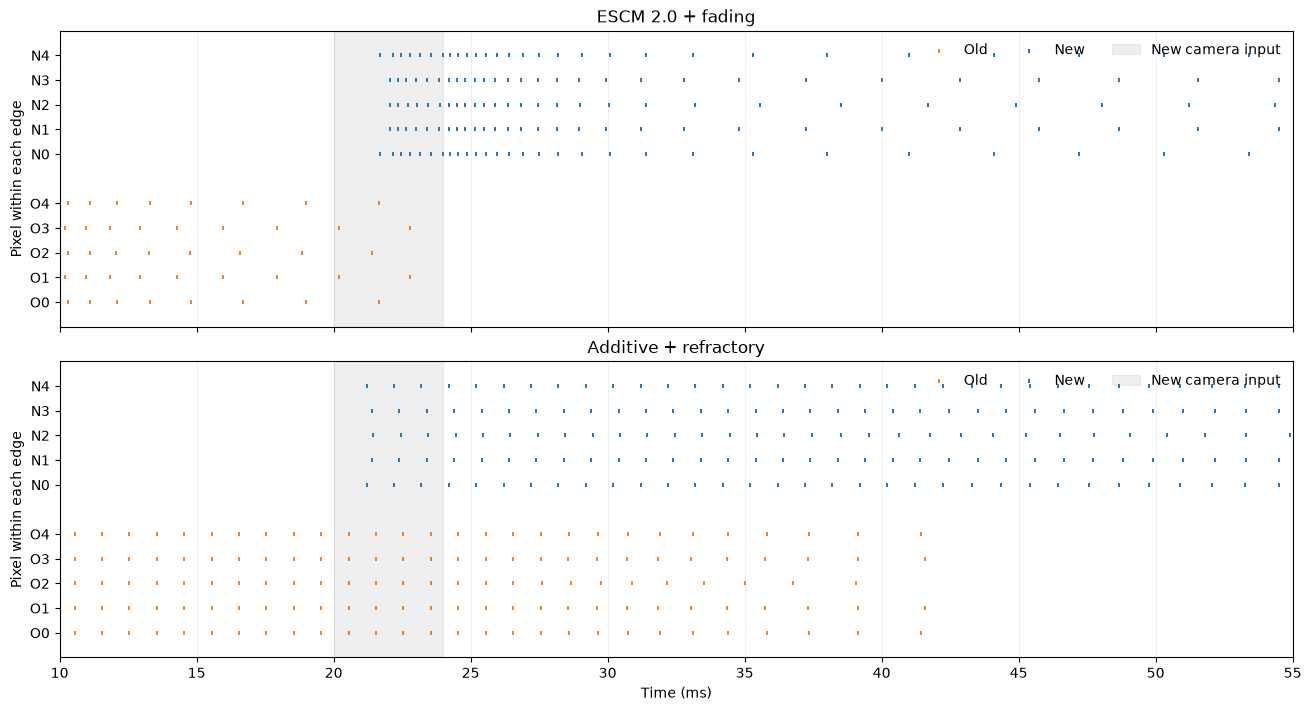

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
for ax, model in zip(axes, settings):
    run = runs[(model, "both")]
    for pop, ids, color in (("Old", old, "tab:orange"), ("New", new, "tab:blue")):
        for k, pixel in enumerate(ids):
            mask = (run["i"] == pixel) & (run["t"] >= 10) & (run["t"] <= 55)
            ax.scatter(run["t"][mask], np.full(mask.sum(), k + (0 if pop == "Old" else 6)),
                       s=8, marker="|", linewidth=1.4, color=color, label=pop if k == 0 else None)
    ax.axvspan(20., 24., color="grey", alpha=0.12, label="New camera input")
    ax.set(title=model, ylabel="Pixel within each edge", ylim=(-1, 11),
           yticks=[0, 1, 2, 3, 4, 6, 7, 8, 9, 10],
           yticklabels=["O0", "O1", "O2", "O3", "O4", "N0", "N1", "N2", "N3", "N4"])
    ax.grid(axis="x", alpha=0.2)
    ax.legend(loc="upper right", ncol=3, frameon=False)
axes[-1].set(xlabel="Time (ms)", xlim=(10, 55))
plt.show()

## 7. Interpretation and decision rule

The table below summarizes the **measured** differences during the first persistence window; it does not automatically label a mechanism as causal.

- **Lower inhibitory current** in additive ESCM than in the approved reference points toward inadequate recruitment of surround inhibition (which may be a consequence of altered spiking).
- **Higher excitatory current** alongside comparable inhibition points toward excessive additive recurrent drive.
- **Both differences** suggest an excitation–inhibition imbalance; changing a single global inhibitory gain may be insufficient, because the new edge also depends on inhibition.
- **Similar currents with different spike outputs** point toward the membrane dynamics, especially the different refractory conditions. In that case, the next controlled comparison should hold refractoriness fixed across models.

The next scientifically useful experiment should manipulate **only the identified pathway**, with isolated persistence controls. Do not add STD or retune a parameter grid before interpreting this diagnostic.

**Boundary:** This experiment uses one vertical-edge schedule and the parameter settings selected in Notebook 25. It is diagnostic evidence, not a claim of matching the full five-geometry benchmark.

In [7]:
phase = "Persistence 1"
ref = old_both.query("model == 'ESCM 2.0 + fading' and phase == @phase").iloc[0]
add = old_both.query("model == 'Additive + refractory' and phase == @phase").iloc[0]
readout = pd.DataFrame({
    "Quantity": ["Old-edge excitation", "Old-edge inhibition", "Old-edge external drive", "Old-edge net drive"],
    "ESCM 2.0 + fading": [ref.Iexc, ref.Iinh, ref.Iext, ref.net_drive],
    "Additive + refractory": [add.Iexc, add.Iinh, add.Iext, add.net_drive],
})
readout["Additive minus reference"] = readout["Additive + refractory"] - readout["ESCM 2.0 + fading"]
display(readout.round(3))

print("Old-edge output spikes during the first persistence window:")
for model in settings:
    r = runs[(model, "both")]
    print(f"  {model}: {counts(r, old, 32., 42.).tolist()} (pixel order: top to bottom)")
print("\nInterpret the measured current balance together with the raster before choosing an intervention.")

,Quantity,ESCM 2.0 + fading,Additive + refractory,Additive minus reference
0,Old-edge excitation,0.424,9.533,9.109
1,Old-edge inhibition,2.193,2.993,0.799
2,Old-edge external drive,0.002,0.002,0.000
3,Old-edge net drive,-1.768,6.542,8.310


Old-edge output spikes during the first persistence window:
  ESCM 2.0 + fading: [0, 0, 0, 0, 0] (pixel order: top to bottom)
  Additive + refractory: [6, 6, 5, 6, 6] (pixel order: top to bottom)

Interpret the measured current balance together with the raster before choosing an intervention.
